In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df=pd.read_csv("../../data/Nanoparticles_Synthesis_Dataset - Chemical_Synthesis.csv")

In [4]:
df.head()

,NanoParticles,Precursor Feeding Rate (ml/min),Precursor,Precursor Concentration,Unit,Reducing Agent,Reducing Agent Concentration,Unit.1,Stabilizing Agent,Stabilizing Agent Concentration,...,Agitation,Stirring rate(rpm),Time(min),Average Size(nm),Min Size(nm),Max Size(nm),Method to record sizes,Shape,Reference,Title of Article
0,CuMoO4,2.5,Cu2+ solution,0.005,mM,MoO42- aq solution,0.005,mM,NaN,NaN,...,Vigorous Stirring,NaN,NaN,98,NaN,NaN,SEM,NaN,C1,Facile chemical synthesis and structure charac...
1,CuMoO4,10.0,Cu2+ solution,0.005,mM,MoO42- aq solution,0.01,mM,NaN,NaN,...,Vigorous Stirring,NaN,NaN,11,NaN,NaN,SEM,NaN,C1,Facile chemical synthesis and structure charac...
2,CuMoO4,40.0,Cu2+ solution,0.005,mM,MoO42- aq solution,0.1,mM,NaN,NaN,...,Vigorous Stirring,NaN,NaN,80,NaN,NaN,SEM,NaN,C1,Facile chemical synthesis and structure charac...
3,CuMoO4,10.0,Cu2+ solution,0.01,mM,MoO42- aq solution,0.005,mM,NaN,NaN,...,Vigorous Stirring,NaN,NaN,124,NaN,NaN,SEM,NaN,C1,Facile chemical synthesis and structure charac...
4,CuMoO4,40.0,Cu2+ solution,0.01,mM,MoO42- aq solution,0.01,mM,NaN,NaN,...,Vigorous Stirring,NaN,NaN,139,NaN,NaN,SEM,NaN,C1,Facile chemical synthesis and structure charac...


In [5]:
df.describe(include="all")

,NanoParticles,Precursor Feeding Rate (ml/min),Precursor,Precursor Concentration,Unit,Reducing Agent,Reducing Agent Concentration,Unit.1,Stabilizing Agent,Stabilizing Agent Concentration,...,Agitation,Stirring rate(rpm),Time(min),Average Size(nm),Min Size(nm),Max Size(nm),Method to record sizes,Shape,Reference,Title of Article
count,166,34.000000,166,153,144,164,149,142,95,84.000000,...,121,56,124.000000,147,50.000000,50.000000,146,103,164,164
unique,27,NaN,31,26,9,26,34,12,31,NaN,...,9,11,NaN,121,NaN,NaN,10,11,47,46
top,AgNps,NaN,AgNO3,1,M,NaBH4,1,M,Polyvinylpyrrolidone (PVP),NaN,...,Magnetic stirring,400,NaN,20,NaN,NaN,TEM,Spherical,C2,Effect of Calcination Temperature and Time on ...
freq,26,NaN,67,43,88,31,19,80,25,NaN,...,52,32,NaN,8,NaN,NaN,41,64,18,18
mean,NaN,9.723529,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.978429,...,NaN,NaN,155.564516,NaN,15.716000,111.700000,NaN,NaN,NaN,NaN
std,NaN,14.609836,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.623460,...,NaN,NaN,640.635549,NaN,14.108853,187.595136,NaN,NaN,NaN,NaN
min,NaN,0.200000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.001000,...,NaN,NaN,10.000000,NaN,1.000000,2.600000,NaN,NaN,NaN,NaN
25%,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.060000,...,NaN,NaN,30.000000,NaN,9.250000,26.250000,NaN,NaN,NaN,NaN
50%,NaN,2.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.300000,...,NaN,NaN,60.000000,NaN,13.000000,44.000000,NaN,NaN,NaN,NaN
75%,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,...,NaN,NaN,120.000000,NaN,15.800000,92.000000,NaN,NaN,NaN,NaN


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 166 entries, 0 to 165
Data columns (total 26 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   NanoParticles                    166 non-null    object 
 1   Precursor Feeding Rate (ml/min)  34 non-null     float64
 2   Precursor                        166 non-null    object 
 3   Precursor Concentration          153 non-null    object 
 4   Unit                             144 non-null    object 
 5   Reducing Agent                   164 non-null    object 
 6   Reducing Agent Concentration     149 non-null    object 
 7   Unit.1                           142 non-null    object 
 8   Stabilizing Agent                95 non-null     object 
 9   Stabilizing Agent Concentration  84 non-null     float64
 10  Unit.2                           82 non-null     object 
 11  Temperature(°C)                  127 non-null    float64
 12  Pressure              

# Data Cleaning

In [7]:
df['Precursor Concentration']

0      0.005
1      0.005
2      0.005
3       0.01
4       0.01
       ...  
161        1
162      500
163     0.01
164      0.1
165        1
Name: Precursor Concentration, Length: 166, dtype: object

In [8]:
print(df['Precursor Concentration'].unique())

['0.005' '0.01' '0.1' '0.9' '1' '5' '10' '0.2' nan '0.5' '4' '0.05'
 '0.001' '0.006' '0.125' '300' '0.00214' '0.0001698' '0.0101922' '0.01018'
 '0.25' '\n' '0.02' '0.04' '0.06' '0.08' '500']


In [9]:
df['Precursor Concentration'] = df['Precursor Concentration'].str.strip()
df['Precursor Concentration'] = pd.to_numeric(df['Precursor Concentration'], errors='coerce')

In [10]:
df['Precursor Concentration'].dtype

dtype('float64')

In [11]:
print(df['Reducing Agent Concentration'].unique())

['0.005' '0.01' '0.1' '2.8' '5' '0.25' '1' '0.2' nan '0.5' '50' '500' '2'
 '1.5' '0.6' '0.001' '38.8' '0.02' '10' '0.3' '0.4' '200' '0.00285'
 '0.010567' '0.0105' '6' '0.04' '0.03' '1-10' '0.8' '30' '0.002' '0.06'
 '0.08' '450']


In [12]:
df['Reducing Agent Concentration'] = df['Reducing Agent Concentration'].str.strip()
df['Reducing Agent Concentration'] = pd.to_numeric(df['Reducing Agent Concentration'], errors='coerce')

In [13]:
df['Reducing Agent Concentration'].dtype

dtype('float64')

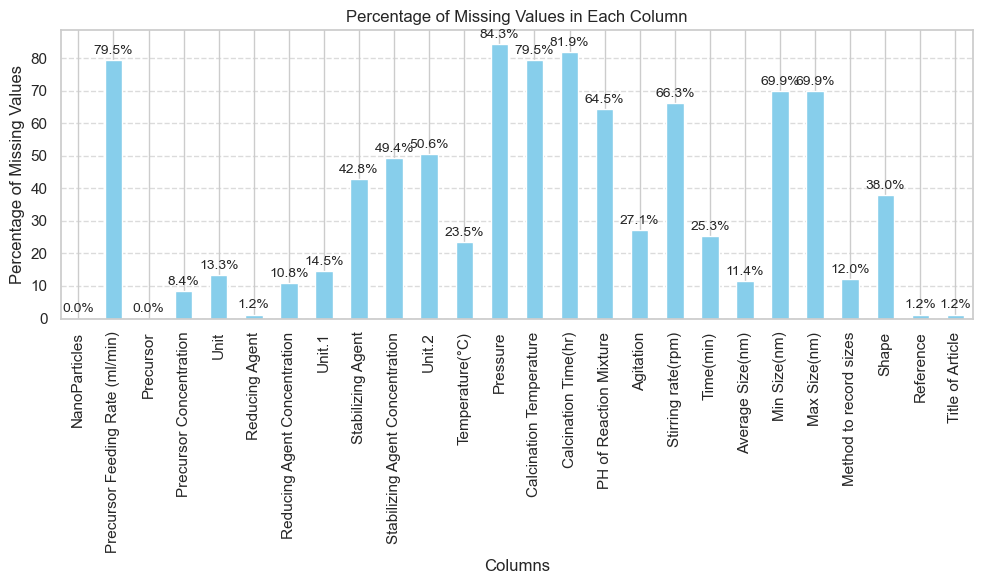

In [56]:
import pandas as pd
import matplotlib.pyplot as plt

# Assuming df is your DataFrame
# Calculate the percentage of missing values for each column
missing_percent = df.isnull().mean() * 100

# Create a bar plot
plt.figure(figsize=(10, 6))
bars = missing_percent.plot(kind='bar', color='skyblue')

# Add percentage values on top of the bars
for bar in bars.patches:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 1, f'{height:.1f}%', 
             ha='center', va='bottom', fontsize=10)

plt.title('Percentage of Missing Values in Each Column')
plt.xlabel('Columns')
plt.ylabel('Percentage of Missing Values')
# plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# Show the plot
plt.show()


In [15]:
df_new=df[['NanoParticles', 'Precursor','Precursor Concentration', 'Unit','Reducing Agent',
         'Reducing Agent Concentration','Unit.1', 'Stabilizing Agent','Stabilizing Agent Concentration','Unit.2',
         'Temperature(°C)','Agitation','Time(min)','Average Size(nm)','Method to record sizes','Shape']]

In [16]:
df_new.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 166 entries, 0 to 165
Data columns (total 16 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   NanoParticles                    166 non-null    object 
 1   Precursor                        166 non-null    object 
 2   Precursor Concentration          152 non-null    float64
 3   Unit                             144 non-null    object 
 4   Reducing Agent                   164 non-null    object 
 5   Reducing Agent Concentration     148 non-null    float64
 6   Unit.1                           142 non-null    object 
 7   Stabilizing Agent                95 non-null     object 
 8   Stabilizing Agent Concentration  84 non-null     float64
 9   Unit.2                           82 non-null     object 
 10  Temperature(°C)                  127 non-null    float64
 11  Agitation                        121 non-null    object 
 12  Time(min)             

In [17]:
#Dropping the rows which have no Reducing Agent
df_new = df_new.dropna(subset=['Reducing Agent'])
df_new.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 164 entries, 0 to 165
Data columns (total 16 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   NanoParticles                    164 non-null    object 
 1   Precursor                        164 non-null    object 
 2   Precursor Concentration          152 non-null    float64
 3   Unit                             144 non-null    object 
 4   Reducing Agent                   164 non-null    object 
 5   Reducing Agent Concentration     148 non-null    float64
 6   Unit.1                           142 non-null    object 
 7   Stabilizing Agent                95 non-null     object 
 8   Stabilizing Agent Concentration  84 non-null     float64
 9   Unit.2                           82 non-null     object 
 10  Temperature(°C)                  127 non-null    float64
 11  Agitation                        121 non-null    object 
 12  Time(min)             

In [18]:
#Finding the no of missing values in all columns
df_new.isna().sum()

NanoParticles                       0
Precursor                           0
Precursor Concentration            12
Unit                               20
Reducing Agent                      0
Reducing Agent Concentration       16
Unit.1                             22
Stabilizing Agent                  69
Stabilizing Agent Concentration    80
Unit.2                             82
Temperature(°C)                    37
Agitation                          43
Time(min)                          40
Average Size(nm)                   19
Method to record sizes             18
Shape                              61
dtype: int64

In [19]:
df_new['Precursor Concentration'] = df_new['Precursor Concentration'].fillna(df_new['Precursor Concentration'].mean())
df_new['Reducing Agent Concentration'] = df_new['Reducing Agent Concentration'].fillna(df_new['Reducing Agent Concentration'].mean())

In [20]:
df_new['Unit'].mode()

0    M
Name: Unit, dtype: object

In [21]:
df_new['Unit.1'].mode()

0    M
Name: Unit.1, dtype: object

In [22]:
df_new['Unit'] = df_new['Unit'].fillna(df_new['Unit'].mode().iloc[0])
df_new['Unit.1'] = df_new['Unit.1'].fillna(df_new['Unit.1'].mode().iloc[0])

In [23]:
df_new.isna().sum()

NanoParticles                       0
Precursor                           0
Precursor Concentration             0
Unit                                0
Reducing Agent                      0
Reducing Agent Concentration        0
Unit.1                              0
Stabilizing Agent                  69
Stabilizing Agent Concentration    80
Unit.2                             82
Temperature(°C)                    37
Agitation                          43
Time(min)                          40
Average Size(nm)                   19
Method to record sizes             18
Shape                              61
dtype: int64

In [24]:
mean_value = df_new['Stabilizing Agent Concentration'].mean()

mask = df_new['Stabilizing Agent'].notna() & df_new['Stabilizing Agent Concentration'].isna()
df_new.loc[mask, 'Stabilizing Agent Concentration'] = mean_value


In [25]:
df_new.isna().sum()

NanoParticles                       0
Precursor                           0
Precursor Concentration             0
Unit                                0
Reducing Agent                      0
Reducing Agent Concentration        0
Unit.1                              0
Stabilizing Agent                  69
Stabilizing Agent Concentration    68
Unit.2                             82
Temperature(°C)                    37
Agitation                          43
Time(min)                          40
Average Size(nm)                   19
Method to record sizes             18
Shape                              61
dtype: int64

In [26]:
mode_value = df_new['Unit.2'].mode().iloc[0]

mask_1 = df_new['Stabilizing Agent Concentration'].notna() & df_new['Unit.2'].isna()
df_new.loc[mask_1, 'Unit.2'] = mode_value

In [27]:
df_new.isna().sum()

NanoParticles                       0
Precursor                           0
Precursor Concentration             0
Unit                                0
Reducing Agent                      0
Reducing Agent Concentration        0
Unit.1                              0
Stabilizing Agent                  69
Stabilizing Agent Concentration    68
Unit.2                             68
Temperature(°C)                    37
Agitation                          43
Time(min)                          40
Average Size(nm)                   19
Method to record sizes             18
Shape                              61
dtype: int64

In [28]:
df_new['Stabilizing Agent'] = df_new['Stabilizing Agent'].fillna('No Stabilizing Agent')
df_new['Stabilizing Agent Concentration'] = df_new['Stabilizing Agent Concentration'].fillna(0)
df_new['Unit.2'] = df_new['Unit.2'].fillna('0')

In [29]:
df_new.isna().sum()

NanoParticles                       0
Precursor                           0
Precursor Concentration             0
Unit                                0
Reducing Agent                      0
Reducing Agent Concentration        0
Unit.1                              0
Stabilizing Agent                   0
Stabilizing Agent Concentration     0
Unit.2                              0
Temperature(°C)                    37
Agitation                          43
Time(min)                          40
Average Size(nm)                   19
Method to record sizes             18
Shape                              61
dtype: int64

In [30]:
df_new['Temperature(°C)'] = df_new['Temperature(°C)'].fillna(25)

In [31]:
df_new['Agitation'] = df_new['Agitation'].fillna('No Stirring')

In [32]:
df_new['Time(min)'] = df_new['Time(min)'].fillna(df_new['Time(min)'].mean())

In [33]:
df_new['Average Size(nm)'] = pd.to_numeric(df_new['Average Size(nm)'], errors='coerce')
df_new['Average Size(nm)'].dtype

dtype('float64')

In [34]:
df_new['Average Size(nm)'] = df_new['Average Size(nm)'].fillna(df_new['Average Size(nm)'].mean())

In [35]:
df_new['Method to record sizes'] = df_new['Method to record sizes'].fillna(df_new['Method to record sizes'].mode().iloc[0])

In [36]:
df_new['Shape'].mode()

0    Spherical
Name: Shape, dtype: object

In [37]:
df_new['Shape'] = df_new['Shape'].fillna(df_new['Shape'].mode().iloc[0])

In [38]:
df_new.isna().sum()

NanoParticles                      0
Precursor                          0
Precursor Concentration            0
Unit                               0
Reducing Agent                     0
Reducing Agent Concentration       0
Unit.1                             0
Stabilizing Agent                  0
Stabilizing Agent Concentration    0
Unit.2                             0
Temperature(°C)                    0
Agitation                          0
Time(min)                          0
Average Size(nm)                   0
Method to record sizes             0
Shape                              0
dtype: int64

In [39]:
df_new.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 164 entries, 0 to 165
Data columns (total 16 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   NanoParticles                    164 non-null    object 
 1   Precursor                        164 non-null    object 
 2   Precursor Concentration          164 non-null    float64
 3   Unit                             164 non-null    object 
 4   Reducing Agent                   164 non-null    object 
 5   Reducing Agent Concentration     164 non-null    float64
 6   Unit.1                           164 non-null    object 
 7   Stabilizing Agent                164 non-null    object 
 8   Stabilizing Agent Concentration  164 non-null    float64
 9   Unit.2                           164 non-null    object 
 10  Temperature(°C)                  164 non-null    float64
 11  Agitation                        164 non-null    object 
 12  Time(min)             

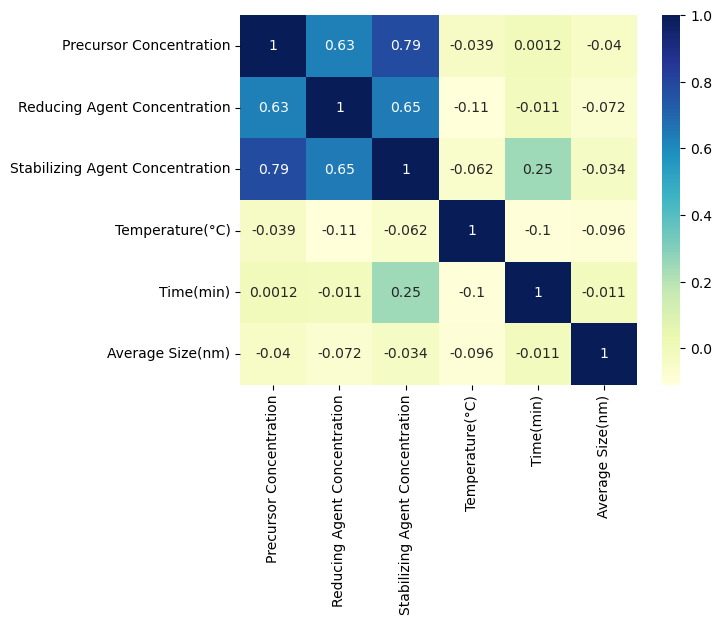

In [40]:
dataplot = sns.heatmap(df_new.corr(), cmap="YlGnBu", annot=True)

In [64]:
df_new.corr()

,Precursor Concentration,Reducing Agent Concentration,Stabilizing Agent Concentration,Temperature(°C),Time(min),Average Size(nm)
Precursor Concentration,1.000000,0.631196,0.785186,-0.038684,0.001238,-0.040274
Reducing Agent Concentration,0.631196,1.000000,0.648121,-0.109119,-0.010561,-0.071841
Stabilizing Agent Concentration,0.785186,0.648121,1.000000,-0.062273,0.248728,-0.033814
Temperature(°C),-0.038684,-0.109119,-0.062273,1.000000,-0.100618,-0.095608
Time(min),0.001238,-0.010561,0.248728,-0.100618,1.000000,-0.011492
Average Size(nm),-0.040274,-0.071841,-0.033814,-0.095608,-0.011492,1.000000


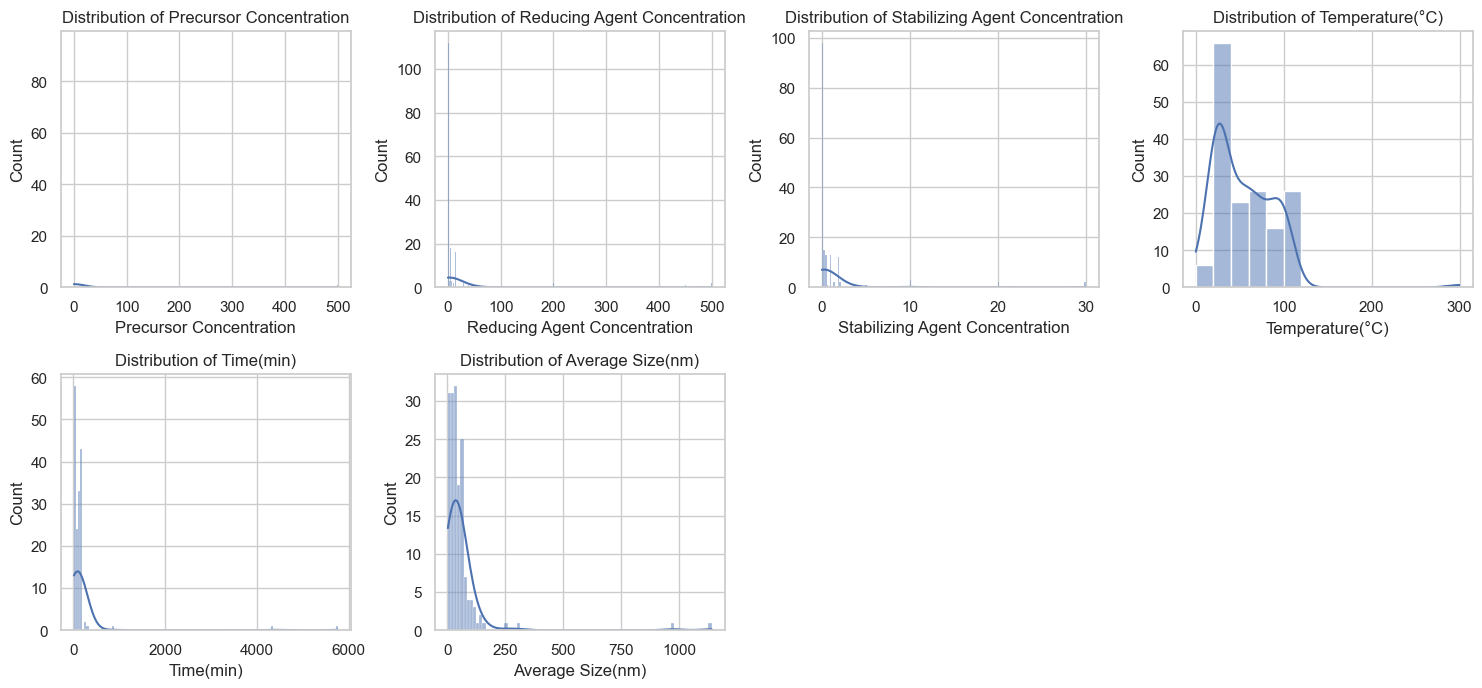

In [41]:
# Set the style of the visualization
sns.set(style="whitegrid")

# Plot distributions of numerical features
numerical_columns = df_new.select_dtypes(include=['float64', 'int64']).columns

plt.figure(figsize=(15, 10))
for i, col in enumerate(numerical_columns, 1):
    plt.subplot(3, 4, i)
    sns.histplot(df_new[col], kde=True)
    plt.title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

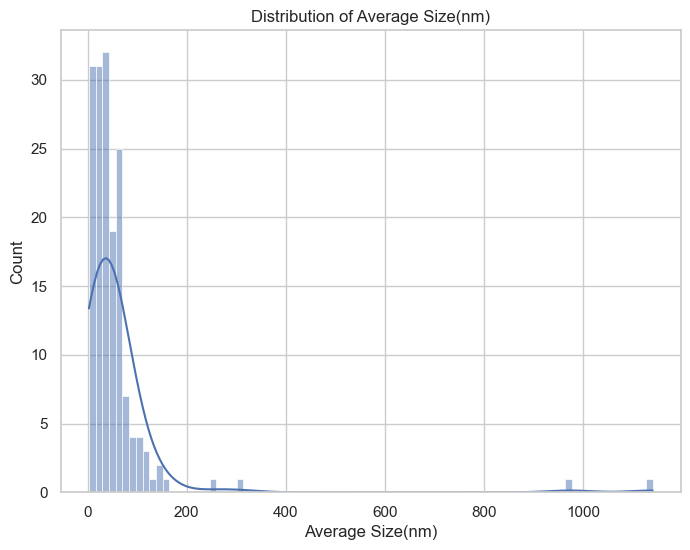

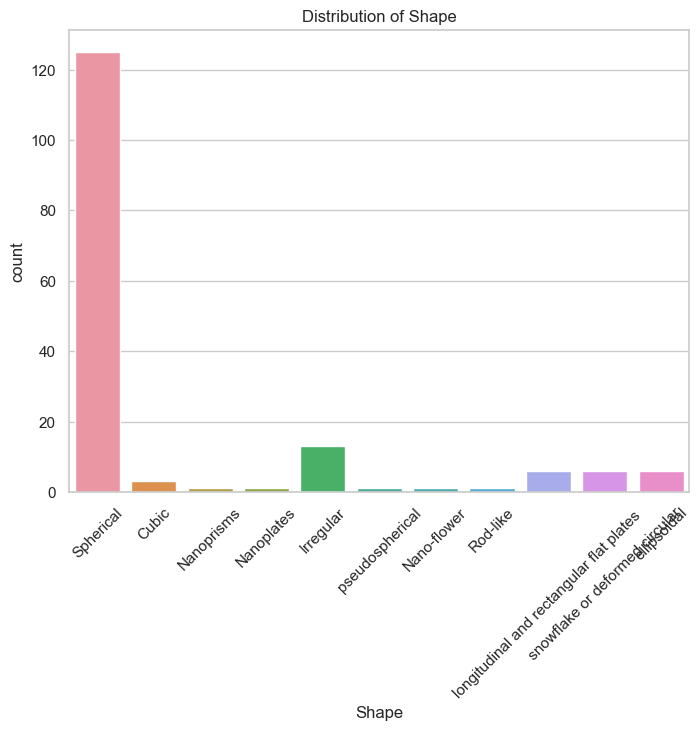

In [59]:
# Distribution of Average Size(nm)
plt.figure(figsize=(8, 6))
sns.histplot(df_new['Average Size(nm)'], kde=True)
plt.title('Distribution of Average Size(nm)')
plt.show()

# Distribution of Shape
plt.figure(figsize=(8, 6))
sns.countplot(data=df_new, x='Shape')
plt.title('Distribution of Shape')
plt.xticks(rotation=45)
plt.show()

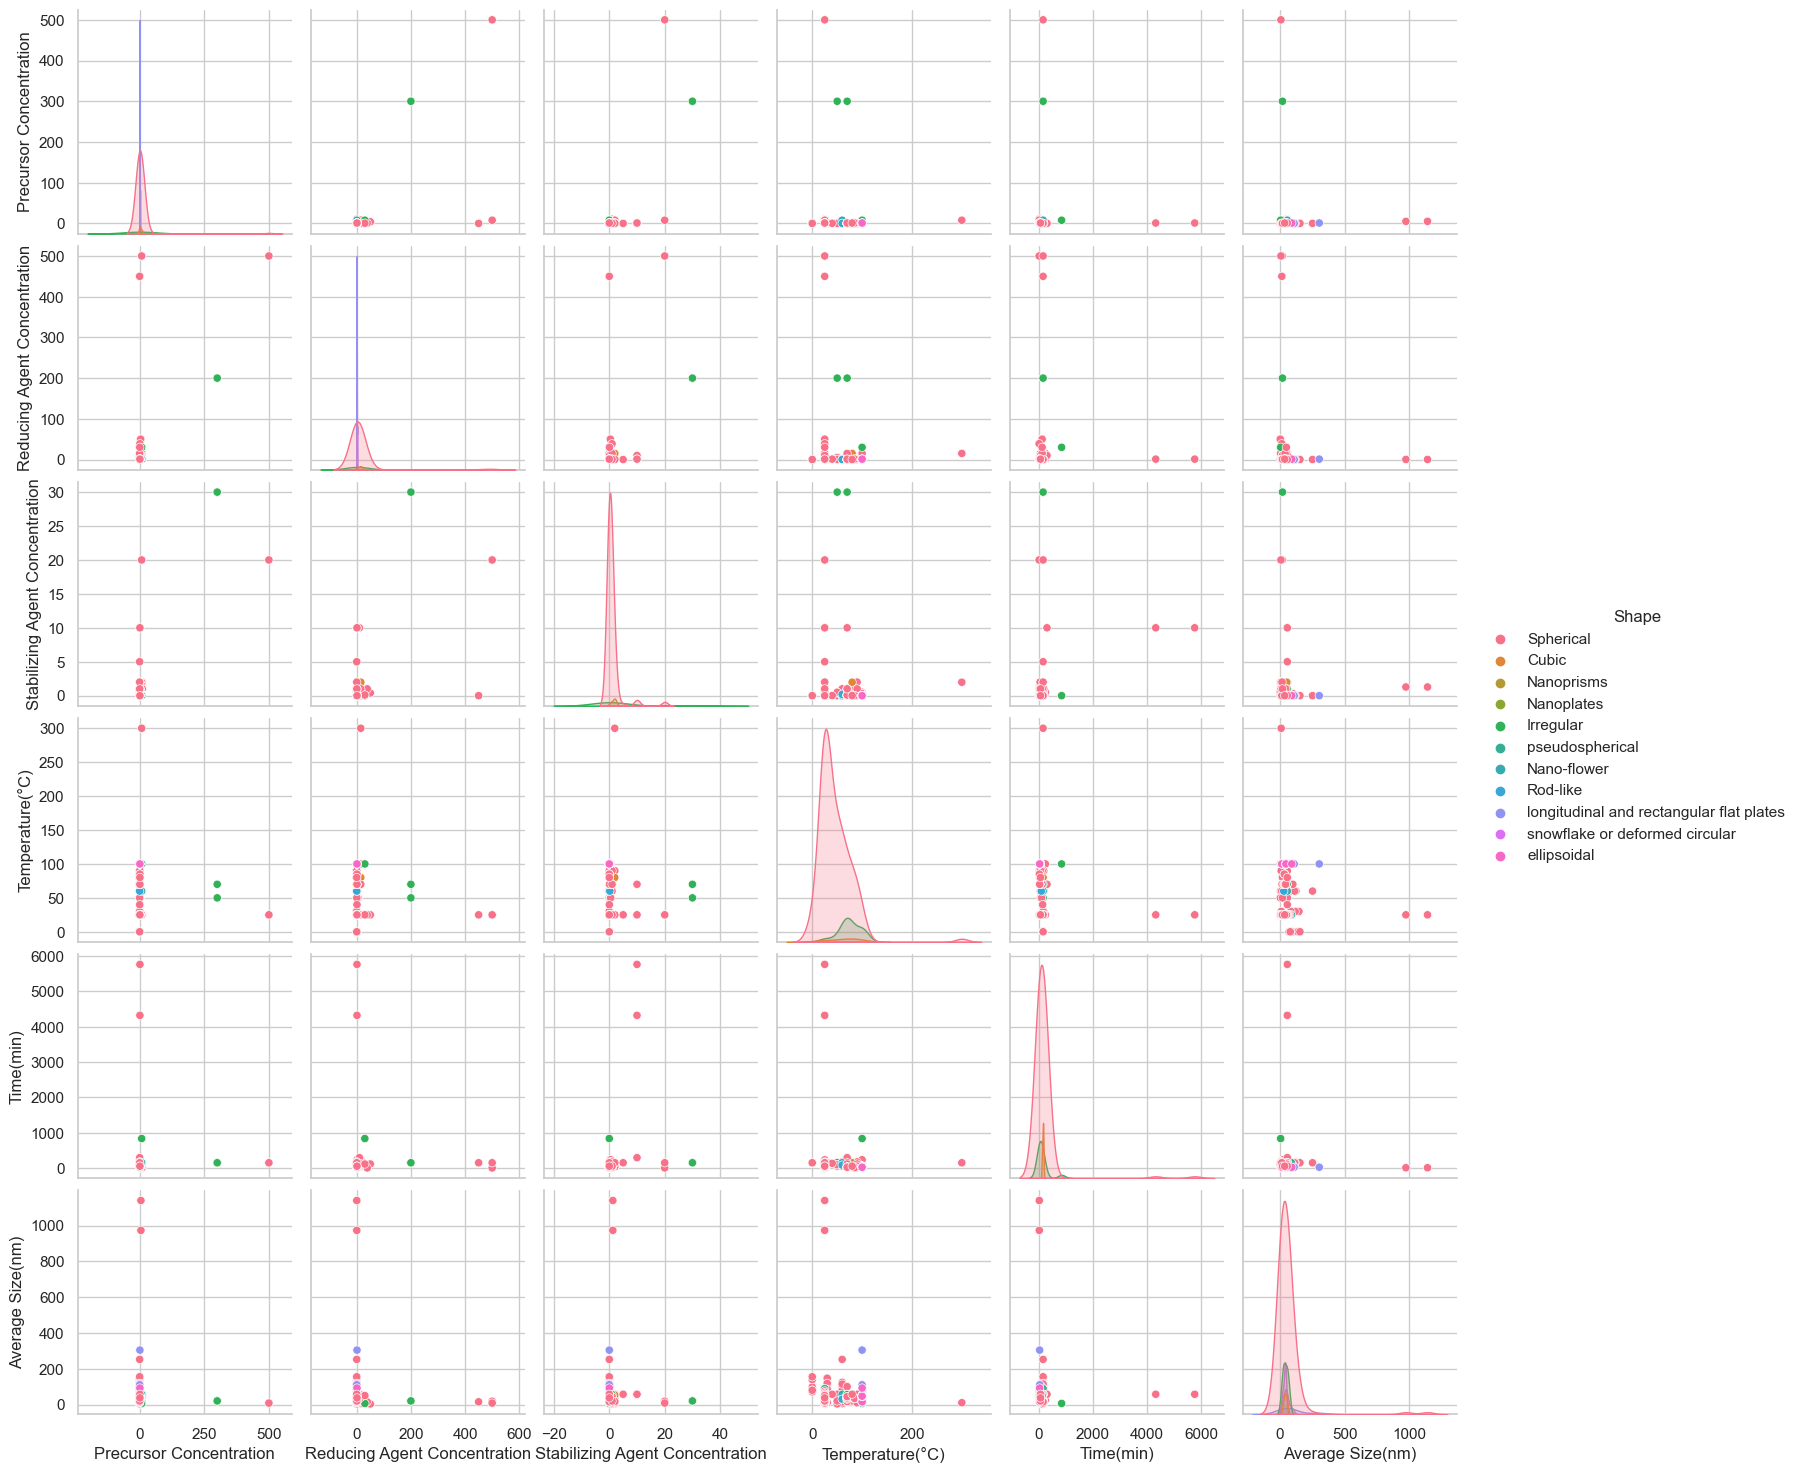

In [43]:
# Pair plot for numerical features
sns.pairplot(df_new, diag_kind='kde', kind='scatter', hue='Shape')
plt.show()

Feature ranking for Average Size(nm):
1. Feature Agitation (0.19050070723604612)
2. Feature Precursor Concentration (0.1702746161504071)
3. Feature Reducing Agent (0.14605281921566593)
4. Feature Stabilizing Agent Concentration (0.09472250270929734)
5. Feature Time(min) (0.09230471699620203)
6. Feature NanoParticles (0.05719051359347988)
7. Feature Reducing Agent Concentration (0.05226587159421543)
8. Feature Unit (0.04307492868787373)
9. Feature Method to record sizes (0.04048072700990163)
10. Feature Stabilizing Agent (0.0318907948080478)
11. Feature Unit.2 (0.028649084071428965)
12. Feature Precursor (0.018952378891221443)
13. Feature Unit.1 (0.017813758361440956)
14. Feature Temperature(°C) (0.01582658067477156)


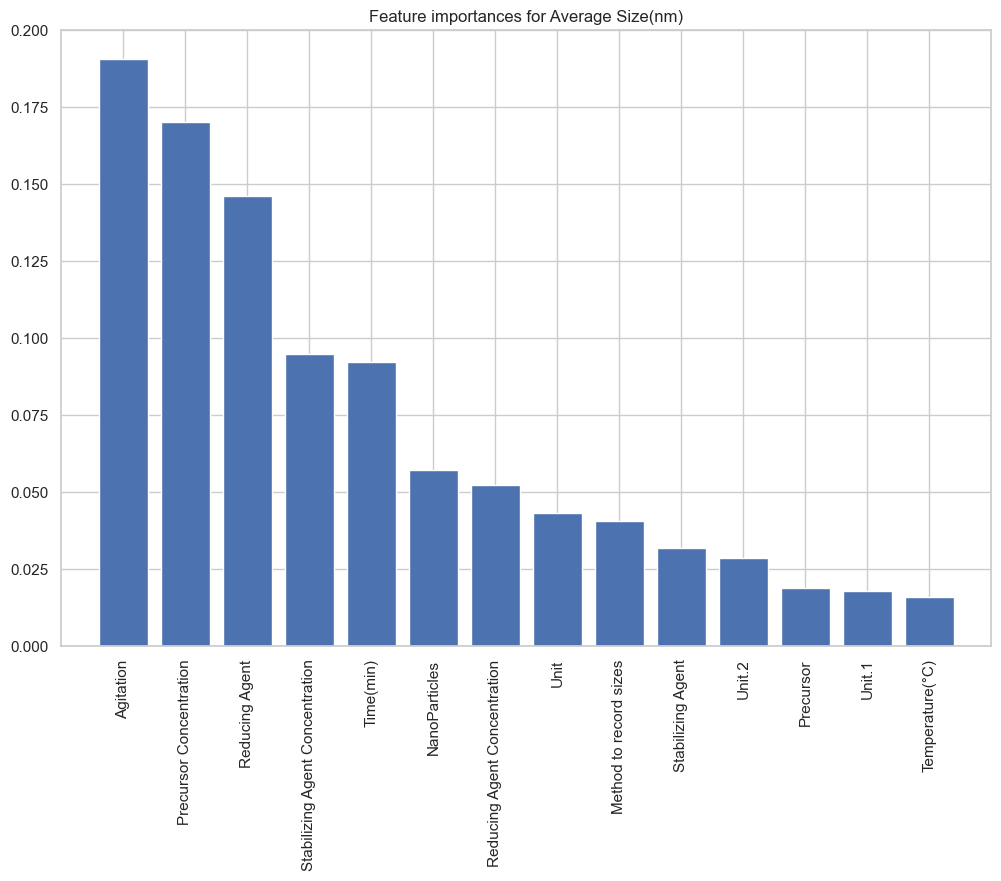

In [60]:
# Feature importance for Average Size(nm)
importances = regressor.feature_importances_
indices = np.argsort(importances)[::-1]

# Print the feature ranking
print("Feature ranking for Average Size(nm):")

for f in range(X_train_size.shape[1]):
    print(f"{f + 1}. Feature {X_train_size.columns[indices[f]]} ({importances[indices[f]]})")

# Plot the feature importances
plt.figure(figsize=(12, 8))
plt.title("Feature importances for Average Size(nm)")
plt.bar(range(X_train_size.shape[1]), importances[indices], align="center")
plt.xticks(range(X_train_size.shape[1]), X_train_size.columns[indices], rotation=90)
plt.xlim([-1, X_train_size.shape[1]])
plt.show()

Feature ranking for Shape:
1. Feature Reducing Agent (0.21842915707763544)
2. Feature Temperature(°C) (0.1467854392515459)
3. Feature Stabilizing Agent (0.0966234103455045)
4. Feature NanoParticles (0.07756132468672776)
5. Feature Precursor Concentration (0.06878746172816544)
6. Feature Method to record sizes (0.060740939406008214)
7. Feature Precursor (0.060318954777107206)
8. Feature Stabilizing Agent Concentration (0.054189950886509894)
9. Feature Reducing Agent Concentration (0.05308645092463389)
10. Feature Time(min) (0.052359401574588384)
11. Feature Agitation (0.04067271305069844)
12. Feature Unit.2 (0.03754837098586204)
13. Feature Unit (0.019926486764074065)
14. Feature Unit.1 (0.012969938540938825)


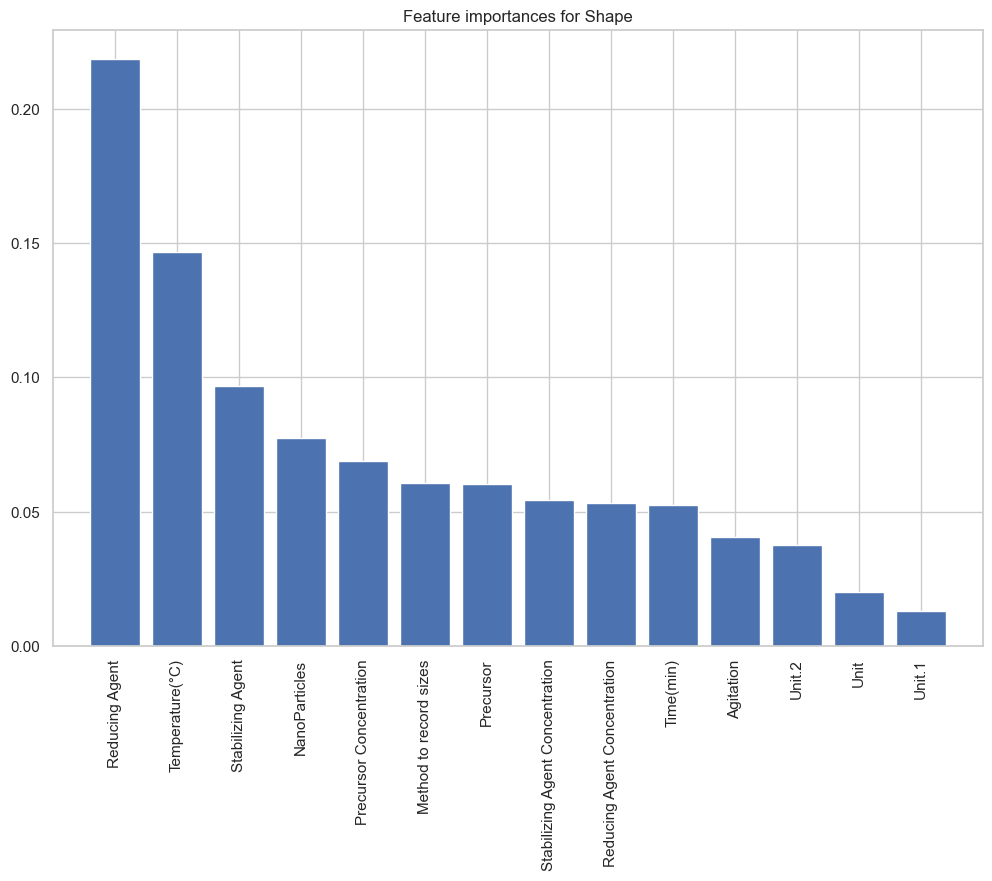

In [61]:
# Feature importance for Shape
importances_shape = classifier.feature_importances_
indices_shape = np.argsort(importances_shape)[::-1]

# Print the feature ranking
print("Feature ranking for Shape:")

for f in range(X_train_shape.shape[1]):
    print(f"{f + 1}. Feature {X_train_shape.columns[indices_shape[f]]} ({importances_shape[indices_shape[f]]})")

# Plot the feature importances
plt.figure(figsize=(12, 8))
plt.title("Feature importances for Shape")
plt.bar(range(X_train_shape.shape[1]), importances_shape[indices_shape], align="center")
plt.xticks(range(X_train_shape.shape[1]), X_train_shape.columns[indices_shape], rotation=90)
plt.xlim([-1, X_train_shape.shape[1]])
plt.show()

# Predictive Modeling Using Machine Learning

In [47]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [48]:
X = df_new.drop(columns=['Average Size(nm)', 'Shape'])
y_size = df_new['Average Size(nm)']
y_shape = df_new['Shape']

# Encode categorical variables
categorical_columns = X.select_dtypes(include=['object']).columns
encoder = LabelEncoder()

for col in categorical_columns:
    X[col] = encoder.fit_transform(X[col])

# Split the data into training and testing sets for regression and classification
X_train_size, X_test_size, y_train_size, y_test_size = train_test_split(X, y_size, test_size=0.2, random_state=42)
X_train_shape, X_test_shape, y_train_shape, y_test_shape = train_test_split(X, y_shape, test_size=0.2, random_state=42)

# Random Forest Model

In [63]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Initialize the model
regressor = RandomForestRegressor(random_state=42)

# Train the model
regressor.fit(X_train_size, y_train_size)

# Make predictions
y_pred_size = regressor.predict(X_test_size)

# Evaluate the model
mae = mean_absolute_error(y_test_size, y_pred_size)
mse = mean_squared_error(y_test_size, y_pred_size)
r2 = r2_score(y_test_size, y_pred_size)

print(f"Mean Absolute Error (MAE) for Average Size(nm) prediction: {mae}")
print(f"Mean Squared Error (MSE) for Average Size(nm) prediction: {mse}")
print(f"R-squared (R2) Score for Average Size(nm) prediction: {r2}")

Mean Absolute Error (MAE) for Average Size(nm) prediction: 51.145178087417634
Mean Squared Error (MSE) for Average Size(nm) prediction: 9852.818289132105
R-squared (R2) Score for Average Size(nm) prediction: 0.6424481109310544


In [50]:
from sklearn.tree import export_graphviz
import matplotlib.pyplot as plt
from IPython.display import Image
import pydotplus


tree = regressor.estimators_[0]

# Export the tree structure to a dot file
export_graphviz(tree, out_file='tree.dot', feature_names=X.columns, filled=True, rounded=True, special_characters=True)

# Use pydotplus to convert the dot file to an image
dot_data = export_graphviz(tree, out_file=None, feature_names=X.columns, filled=True, rounded=True, special_characters=True)
graph = pydotplus.graph_from_dot_data(dot_data)

# Display the image
Image(graph.create_png())

# Alternatively, save the tree image to a file
graph.write_png("tree.png")

True

In [51]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# Initialize the model
classifier = RandomForestClassifier(random_state=42)

# Train the model
classifier.fit(X_train_shape, y_train_shape)

# Make predictions
y_pred_shape = classifier.predict(X_test_shape)

# Evaluate the model
accuracy = accuracy_score(y_test_shape, y_pred_shape)
classification_rep = classification_report(y_test_shape, y_pred_shape)

print(f"Accuracy for Shape prediction: {accuracy}")
print("Classification Report for Shape prediction:")
print(classification_rep)


Accuracy for Shape prediction: 0.9090909090909091
Classification Report for Shape prediction:
                                           precision    recall  f1-score   support

                                Irregular       0.67      0.67      0.67         3
                                Spherical       0.96      0.96      0.96        26
                              ellipsoidal       1.00      0.67      0.80         3
longitudinal and rectangular flat plates        0.50      1.00      0.67         1

                                 accuracy                           0.91        33
                                macro avg       0.78      0.82      0.77        33
                             weighted avg       0.92      0.91      0.91        33



In [52]:
categorical_columns

Index(['NanoParticles', 'Precursor', 'Unit', 'Reducing Agent', 'Unit.1',
       'Stabilizing Agent', 'Unit.2', 'Agitation', 'Method to record sizes'],
      dtype='object')

# Gradient Boosting Model

In [53]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.svm import SVC
from sklearn.metrics import mean_absolute_error

In [54]:
# Initialize the Gradient Boosting Regressor
gbr = GradientBoostingRegressor(random_state=42)

# Train the model
gbr.fit(X_train_size, y_train_size)

# Make predictions
y_pred_gbr = gbr.predict(X_test_size)

# Evaluate the model
mse_gbr = mean_squared_error(y_test_size, y_pred_gbr)
mae_gbr = mean_absolute_error(y_test_size, y_pred_gbr)
r2_gbr = r2_score(y_test_size, y_pred_gbr)

print(f"Gradient Boosting Regressor - Mean Squared Error (MSE): {mse_gbr}")
print(f"Gradient Boosting Regressor - Mean Absolute Error (MAE): {mae_gbr}")
print(f"Gradient Boosting Regressor - R-squared (R2) Score: {r2_gbr}")


Gradient Boosting Regressor - Mean Squared Error (MSE): 4180.078183192907
Gradient Boosting Regressor - Mean Absolute Error (MAE): 34.199861717897804
Gradient Boosting Regressor - R-squared (R2) Score: 0.8483078844044973


# Support Vector Machine Model

In [55]:
from sklearn.metrics import accuracy_score, classification_report
# Initialize the Support Vector Machine Classifier
svc = SVC(random_state=42)

# Train the model
svc.fit(X_train_shape, y_train_shape)

# Make predictions
y_pred_svc = svc.predict(X_test_shape)

# Evaluate the model
accuracy_svc = accuracy_score(y_test_shape, y_pred_svc)
classification_rep_svc = classification_report(y_test_shape, y_pred_svc)

print(f"Support Vector Machine Classifier - Accuracy: {accuracy_svc}")
print("Support Vector Machine Classifier - Classification Report:")
print(classification_rep_svc)


Support Vector Machine Classifier - Accuracy: 0.7878787878787878
Support Vector Machine Classifier - Classification Report:
                                           precision    recall  f1-score   support

                                Irregular       0.00      0.00      0.00         3
                                Spherical       0.79      1.00      0.88        26
                              ellipsoidal       0.00      0.00      0.00         3
longitudinal and rectangular flat plates        0.00      0.00      0.00         1

                                 accuracy                           0.79        33
                                macro avg       0.20      0.25      0.22        33
                             weighted avg       0.62      0.79      0.69        33



sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
sklearn\metrics\_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
